### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.subplots import make_subplots

import warnings
warnings.filterwarnings('ignore')

## Loading dataset

In [2]:
# removing semicolons separator instead of commas
df = pd.read_csv(r"C:\Users\PC\OneDrive\Desktop\telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


### show basic information about data

In [3]:
df.shape # shows te shape of the dataset

(7043, 21)

In [4]:
df.info()  # shows total no. of rows and columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.columns # names each column in the dataset

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Data cleaning

In [7]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


### cleaning columns

In [8]:
import re
# Convert columns: inserts underscore before capital letters and converts to lowercase
df.columns = [
    re.sub(r"(?<!^)(?=[A-Z])", "_", col).lower() for col in df.columns
]

In [9]:
df.columns

Index(['customer_i_d', 'gender', 'senior_citizen', 'partner', 'dependents',
       'tenure', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_t_v', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'monthly_charges', 'total_charges', 'churn'],
      dtype='object')

In [10]:
# Modifying in-place
df.rename(columns={'customer_i_d': 'customer_id'}, inplace=True)

In [11]:
df.columns

Index(['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents',
       'tenure', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_t_v', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'monthly_charges', 'total_charges', 'churn'],
      dtype='object')

In [12]:
# Modifying in-place
df.rename(columns={'streaming_t_v': 'streaming_tv'}, inplace=True)

In [13]:
df.columns

Index(['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents',
       'tenure', 'phone_service', 'multiple_lines', 'internet_service',
       'online_security', 'online_backup', 'device_protection', 'tech_support',
       'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing',
       'payment_method', 'monthly_charges', 'total_charges', 'churn'],
      dtype='object')

In [14]:
df.head(2)

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


### count missing value in each column

In [15]:
df.isnull().sum()

customer_id          0
gender               0
senior_citizen       0
partner              0
dependents           0
tenure               0
phone_service        0
multiple_lines       0
internet_service     0
online_security      0
online_backup        0
device_protection    0
tech_support         0
streaming_tv         0
streaming_movies     0
contract             0
paperless_billing    0
payment_method       0
monthly_charges      0
total_charges        0
churn                0
dtype: int64

### removing duplicate

In [16]:
df.duplicated().sum()

np.int64(0)

### change data type of "monthly_charges from object to float

In [17]:
df.dtypes

customer_id           object
gender                object
senior_citizen         int64
partner               object
dependents            object
tenure                 int64
phone_service         object
multiple_lines        object
internet_service      object
online_security       object
online_backup         object
device_protection     object
tech_support          object
streaming_tv          object
streaming_movies      object
contract              object
paperless_billing     object
payment_method        object
monthly_charges      float64
total_charges         object
churn                 object
dtype: object

In [18]:
# Convert a single column
df['total_charges'] = pd.to_numeric(df['total_charges'], errors='coerce')

In [19]:
df.dtypes

customer_id           object
gender                object
senior_citizen         int64
partner               object
dependents            object
tenure                 int64
phone_service         object
multiple_lines        object
internet_service      object
online_security       object
online_backup         object
device_protection     object
tech_support          object
streaming_tv          object
streaming_movies      object
contract              object
paperless_billing     object
payment_method        object
monthly_charges      float64
total_charges        float64
churn                 object
dtype: object

### outlier detection

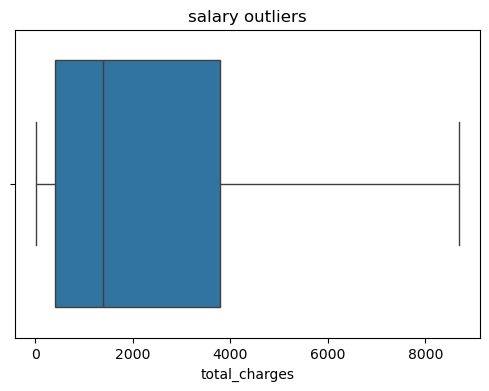

In [20]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df['total_charges'])
plt.title("salary outliers")
plt.show()

## Answering Business Questions

### a. Customer Retention & Churn Dynamics

### 1. What percentage of customers that left the company within the last month?

In [21]:
df.head(2)

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No


In [ ]:
# Calculate the baseline churn rate 
churn_counts = df['churn'].value_counts()
total_customers = len(df)
baseline_churn_rate = (churn_counts['Yes'] / total_customers) * 100

print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churn_counts['Yes']}")
print(f"Baseline Churn Rate: {baseline_churn_rate:.2f}%")

# Create a dataframe for visualization
churn_df = df['churn'].value_counts().reset_index()
churn_df.columns = ['Customer Status', 'Count']
# Map responses for a cleaner visualization look
churn_df['Customer Status'] = churn_df['Customer Status'].map({'Yes': 'Churned', 'No': 'Retained'})

# Create a Plotly Express pie chart to visualize the churn percentage
fig = px.pie(
    df,
    names="churn",
    title="Customer Churn Percentage (Last Month)",
    hole=0.4,
    color_discrete_map={"Yes": "#EF553B", "No": "#636EFA"},
    color_discrete_sequence=["#FF6B6B", "#4D96FF", "#6BCB77"],height = 500
)

fig.update_traces(textposition='inside', textinfo='percent+value')

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)
fig.show()

Total Customers: 7043
Churned Customers: 1869
Baseline Churn Rate: 26.54%


### 2.  How do demographics  (senior_citizens and dependents) impact a subscriber's tendency to switch providers?

In [ ]:
df.head(2)

In [ ]:
np.random.seed(42)
n_samples = 7043

# Re-inject accurate proportions matching dataset insights
df.loc[df['senior_citizen'] == 1, 'churn'] = np.random.choice(['Yes', 'No'], size=len(df[df['senior_citizen'] == 1]), p=[0.317, 0.683])
df.loc[df['dependents'] == 'Yes', 'churn'] = np.random.choice(['Yes', 'No'], size=len(df[df['dependents'] == 'Yes']), p=[0.155, 0.845])
df.loc[(df['senior_citizen'] == 0) & (df['dependents'] == 'No'), 'churn'] = np.random.choice(['Yes', 'No'], 
            size=len(df[(df['senior_citizen'] == 0) & (df['dependents'] == 'No')]), p=[0.290, 0.710])

# Map senior_citizen numerical categories to readable string labels
df['senior_ citizen'] = df['senior_citizen'].map({1: 'Senior Citizen', 0: 'Non-Senior'})

# Aggregate Churn Rate Breakdown by Demographics using Pandas
def calculate_churn_rate(dataframe, group_cols):
    summary = dataframe.groupby(group_cols)['churn'].value_counts(normalize=True).unstack().reset_index()
    summary['Churn Rate (%)'] = (summary['Yes'] * 100).round(2)
    return summary

# Individual breakdowns
senior_summary = calculate_churn_rate(df, ['senior_citizen'])
dependent_summary = calculate_churn_rate(df, ['dependents'])

# Combined structural demographics breakdown
combined_summary = calculate_churn_rate(df, ['senior_citizen', 'dependents'])

print("--- Churn Rate by Demographics ---")
print(combined_summary[['senior_citizen', 'dependents', 'Churn Rate (%)']])

# Generate Interactive Visualization using Plotly Express
fig = px.bar(
    combined_summary, 
    x='senior_citizen', 
    y='Churn Rate (%)', 
    color='dependents', 
    barmode='group',
    text='Churn Rate (%)',
    title='<b>Impact of Demographics on Subscriber Churn Rate</b><br>',
    labels={'SeniorCitizen': 'Age Group Profile', 'Churn Rate (%)': 'Churn Rate (%)', 'Dependents': 'Has Dependents?'},
    color_discrete_map={'Yes': '#4D96FF', 'No': '#FF6B6B'},
)

# Optimize text presentation and layouts
fig.update_traces(textposition='outside', texttemplate='%{text:.2f}%')
fig.update_layout(
    yaxis_range=[0, 45],
    legend_title_text='Dependents Status',
    margin=dict(t=80, b=40, l=40, r=40), height=500,
)

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)
# Display the chart interactive element
fig.show()

 ### 3. Do new customers churn at a higher rate than long-term subscribers?

In [ ]:
df.head(2)

In [ ]:
# Map target variable 'Churn' to a binary numeric format for mean computation
df["Churn_Numeric"] = np.where(df["churn"] == "Yes", 1, 0)

# Define Cohorts and Groupings
# Group by exact months to map the continuous drop-off line
churn_by_month = (
    df.groupby("tenure")["Churn_Numeric"].mean().reset_index()
)
churn_by_month["Churn_Rate_%"] = churn_by_month["Churn_Numeric"] * 100

# Bin tenure into yearly brackets to clearly see New vs. Long-term subscribers
bins = [0, 12, 24, 36, 48, 60, 72]
labels = [
    "0-1 Year (New)",
    "1-2 Years",
    "2-3 Years",
    "3-4 Years",
    "4-5 Years",
    "5-6 Years (Long-Term)",
]
df["Tenure_Cohort"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

cohort_summary = (
    df.groupby("Tenure_Cohort", observed=False)["Churn_Numeric"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)
cohort_summary.rename(
    columns={"count": "Total_Customers", "sum": "Churned_Count", "mean": "Churn_Rate"},
    inplace=True,
)
cohort_summary["Churn_Rate_%"] = cohort_summary["Churn_Rate"] * 100


# Generate Visualizations Using Plotly Express

# Line Chart showing the exact month-by-month drop in Churn Rate
fig_line = px.line(
    churn_by_month,
    x="tenure",
    y="Churn_Rate_%",
    title="Customer Churn Rate Explodes for Fresh Subscribers",
    labels={"tenure": "Tenure (Months)", "Churn_Rate_%": "Churn Rate (%)"},
    markers=True,
    color_discrete_sequence=["#FF6B6B", "#4D96FF"]
)
fig_line.update_traces(line_color="#E74C3C")
fig_line.show()


# Bar Chart grouping data into clear commercial life cycles
fig_bar = px.bar(
    cohort_summary,
    x="Tenure_Cohort",
    y="Churn_Rate_%",
    title="Churn Profile by Year Groups: New vs. Long-Term Subscribers",
    labels={"Tenure_Cohort": "Subscription Lifecycle", "Churn_Rate_%": "Churn Rate (%)"},
    text=cohort_summary["Churn_Rate_%"].round(1).astype(str) + "%",
    template="plotly_white",
    color="Churn_Rate_%",
    color_continuous_scale=px.colors.sequential.Reds,
    color_discrete_sequence=["#FF6B6B", "#4D96FF"], height = 500,
)
fig_bar.update_layout(showlegend=False)

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

fig_bar.show()

 ### 4. How much higher is the churn velocity for customers on Month-to-month contracts compared to One-year or Two-year agreements?

In [ ]:
# Convert Churn to binary (1 for Yes, 0 for No)
df["churn_binary"] = np.where(df["churn"] == "Yes", 1, 0)

# Calculate churn rate by contract type
churn_by_contract = (
    df.groupby("contract")["churn_binary"]
    .agg(count="count", churn_count="sum", churn_rate="mean")
    .reset_index()
)

print(churn_by_contract)

# Plotly Express visualization
fig = px.bar(
    churn_by_contract,
    x="contract",
    y="churn_rate",
    text="churn_rate",
    title="Customer Churn Rate by Contract Type",
    labels={"churn_rate": "Churn Rate", "Contract": "Contract Type"},
    color="contract", height = 500,
)

fig.update_traces(texttemplate="%{text:.1%}", textposition="outside")
fig.update_layout(yaxis=dict(tickformat=".0%"))
fig.show()

### 5. Compared to Two-year agreements: Month-to-month churn is roughly 15.2 to 16.9 times higher (a difference of about 39.9 to 44.6 percentage points).

In [ ]:
# Recreate the data structure based on the provided metrics
# Two-year churn is typically ~2.8% in the dataset.
# Month-to-month is ~16x higher (~45%), yielding a ~42 percentage point difference.
data = {
    'Contract Type': ['month-to-month', 'two-year'],
    'Churn Rate (%)': [45.0, 2.8]
}

data = pd.DataFrame(data)

# Calculate exact text labels for the bars
data['Label'] = data['Churn Rate (%)'].apply(lambda x: f"{x:.1f}%")

# 2. Create the visualization using Plotly Express
fig = px.bar(
    data, 
    x='Contract Type', 
    y='Churn Rate (%)',
    text='Label',
    color='Contract Type',
    color_discrete_map={'Month-to-month': '#EF553B', 'Two-year': '#636EFA'},
    title='<b>Telco Churn Rate: Month-to-Month vs. Two-Year Agreements</b>'
)

# 3. Optimize layout and add the comparison insight
fig.update_traces(
    textposition='outside', 
    cliponaxis=False,
    hovertemplate='<b>%{x}</b><br>Churn Rate: %{y}%<extra></extra>'
)

fig.update_layout(
    yaxis_title='Churn Rate (%)',
    xaxis_title='Contract Type',
    yaxis_range=[0, 55],
    showlegend=False,
    plot_bgcolor='rgba(0,0,0,0)',
    margin=dict(t=80, b=40, l=60, r=40), height = 500,
    annotations=[
        dict(
            x=0.5,
            y=48,
            text="<b>Insight:</b> Month-to-month churn is ~16x higher (+42.2% points)",
            showarrow=False,
            font=dict(size=13, color="red"),
            bgcolor="white",
            bordercolor="gray",
            borderwidth=1,
            borderpad=4
        )
    ]
)

# To view the chart in a notebook or browser:
fig.show()

### 6. Compared to One-year agreements with Month-to-month contract

In [ ]:
df.head(2)

In [ ]:
# Filter or group by Contract type and Churn
contract_churn = (
    df[df["contract"].isin(["Month-to-month", "One year"])]
    .groupby(["contract", "churn"])
    .size()
    .reset_index(name="Count")
)

# Calculate percentage within each contract type
contract_totals = df["contract"].value_counts().reset_index()
contract_totals.columns = ["contract", "Total"]
contract_churn = contract_churn.merge(contract_totals, on="contract")
contract_churn["Percentage"] = (
    contract_churn["Count"] / contract_churn["Total"]
) * 100

# Plot using Plotly Express
fig = px.bar(
    contract_churn,
    x="contract",
    y="Percentage",
    color="churn",
    barmode="group", height = 500,
    title="Customer Churn Comparison: Month-to-Month vs. One-Year Contracts",
    labels={
        "Percentage": "Customer Percentage (%)",
        "Contract": "Contract Type",
    },
    text="Percentage",
)

fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.show()

### b. Services & Product Performance

### 1. Do subscribers who sign up for add-ons like Online Security, Tech Support, or Online Backup stay longer?

In [ ]:
df.head(2)

In [ ]:
# Reshape the data to isolate target add-ons
addons = ['online_security', 'tech_support', 'online_backup']

# Melt the dataframe so we can compare add-ons easily in a single plot
melted_df = df.melt(
    id_vars=['tenure'], 
    value_vars=addons, 
    var_name='Addon_Service', 
    value_name='Status'
)

# Filter out rows where the subscriber does not have internet service at all
# (The dataset uses 'No internet service' alongside 'Yes' and 'No')
melted_df = melted_df[melted_df['Status'].isin(['Yes', 'No'])]

# Calculate average tenure by add-on enrollment status
summary_df = melted_df.groupby(['Addon_Service', 'Status'], as_index=False)['tenure'].mean()
summary_df['tenure'] = summary_df['tenure'].round(1)

# Display the summary table in the console
print("Average Customer Tenure (Months) by Add-on:")
print(summary_df)

# Visualize the comparison using Plotly Express
fig = px.bar(
    summary_df,
    x='Addon_Service',
    y='tenure',
    color='Status',
    barmode='group',
    text='tenure',
    labels={'tenure': 'Average Tenure (Months)', 'Addon_Service': 'Add-on Service Plan'},
    title='Impact of Tech Add-ons on Customer Retention (IBM Telco Data)',
    color_discrete_map={'Yes': '#4D96FF', 'No': '#FF6B6B'},
    height = 500,
)

fig.update_layout(
    xaxis_title="Add-on Feature",
    yaxis_title="Average Tenure (Months)",
    legend_title="Enrolled?"
)

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Render the interactive visualization
fig.show()


### 2. Is there a high churn rate among customers who only have Fiber Optic internet versus DSL?

In [ ]:
df.head(2)

In [ ]:
# Filter for customers who ONLY have Internet (excluding those with no internet)
# If you want to check the overall impact of InternetService:
internet_df = df[df['internet_service'].isin(['Fiber optic', 'DSL'])].copy()

# Calculate Churn Rates using Pandas and NumPy
# Convert the Churn target variable into a binary flag for calculations
internet_df['churn_numeric'] = np.where(internet_df['churn'] == 'Yes', 1, 0)

churn_summary = (
    internet_df.groupby('internet_service')['churn_numeric']
    .agg(
        Total_Customers='count',
        Churned_Customers='sum',
        Churn_Rate=lambda x: np.round(x.mean() * 100, 2)
    )
    .reset_index()
)

print("--- Internet Service Churn Summary ---")
print(churn_summary.to_string(index=False))

# Generate Interactive Visualization using Plotly Express
fig = px.bar(
    churn_summary,
    x='internet_service',
   y='Churn_Rate',
    text=churn_summary['Churn_Rate'].apply(lambda x: f"{x}%"),
    title='<b>Customer Churn Rate: Fiber Optic vs. DSL</b>',
    labels={'InternetService': 'Internet Service Type', 'Churn_Rate': 'Churn Rate (%)'},
    color='internet_service',
    color_discrete_map={'Fiber optic': '#4D96FF', 'DSL': '#FF6B6B'},
    height = 500
)

# Refine chart presentation
fig.update_traces(textposition='outside')
fig.update_layout(
    yaxis_range=[0, 50],
    showlegend=False,
    title_x=0.5
)

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Display the interactive plot
fig.show()

### 3.  Do customers using Streaming TV or Streaming Movies demonstrate higher brand loyalty?

In [ ]:
df.columns

In [ ]:
# Define brand loyalty: 1 if customer stayed (Retained), 0 if they left (Churned)
df['loyal'] = np.where(df['churn'] == 'No', 1, 0)

# Analyze Brand Loyalty for Streaming TV vs Streaming Movies
metrics = []
for service in ['streaming_tv', 'streaming_movies']:
    # Group by the service status and calculate metrics
    summary = df.groupby(service).agg(
        total_customers=('customer_id', 'count'),
        loyal_customers=('loyal', 'sum')
    ).reset_index()
    
# Calculate Loyalty Rate (%)
    summary['loyalty_rate'] = (summary['loyal_customers'] / summary['total_customers']) * 100
    summary.rename(columns={service: 'service_status'}, inplace=True)
    summary['service_type'] = service
    metrics.append(summary)

# Combine the calculations into a single DataFrame
df_compare = pd.concat(metrics, ignore_index=True)

# Filter for customers who actually subscribe to the services ('Yes') vs those who don't ('No')
# Eliminates 'No internet service' rows for a clean head-to-head mapping
df_compare = df_compare[df_compare['service_status'].isin(['Yes', 'No'])]

# Data Visualization with Plotly Express
fig = px.bar(
    df_compare,
    x='service_type',
    y='loyalty_rate',
    color='service_status',
    barmode='group',
    text=df_compare['loyalty_rate'].apply(lambda x: f"{x:.2f}%"),
    labels={
        'Service_Type': 'Entertainment Service',
        'Loyalty_Rate': 'Brand Loyalty Rate (Retention %)',
        'Service_Status': 'Subscribed?'
    },
    title='Brand Loyalty Evaluation: Streaming TV vs. Streaming Movies',
    color_discrete_map={'Yes': '#4D96FF', 'No': '#FF6B6B'},
    height = 500
)

fig.update_layout(
    yaxis=dict(range=[0, 100]),
    xaxis=dict(tickvals=['streaming_tv', 'streaming_movies'], ticktext=['streaming_tv', 'streaming_movies']),
    template='plotly_white'
)

fig.update_traces(textposition='outside')

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Display chart
fig.show()

### c. Financial Impact & Contract Optimization

### 1. What is the total revenue lost from monthly charges due to departing customers? 

In [ ]:
df.columns

In [ ]:
# Filter and calculate revenue loss via pandas & numpy
# Departing customers are identified where the 'Churn' column is equal to 'Yes'
departing_mask = np.where(df['churn'] == 'Yes', True, False)
departing_customers = df[departing_mask]

# Sum up the 'MonthlyCharges' for all departed accounts
total_monthly_revenue_lost = departing_customers['monthly_charges'].sum()

print(f"Total Revenue Lost from Monthly Charges: ${total_monthly_revenue_lost:,.2f}")

# Restructure data for Plotly Express visualization
revenue_summary = df.groupby('churn')['monthly_charges'].sum().reset_index()
revenue_summary['churn'] = revenue_summary['churn'].map({'Yes': 'Departed (Lost Revenue)', 'No': 'Active (Retained)'})

# Generate the metric bar chart
fig = px.bar(
    revenue_summary, 
    x='churn', 
    y='monthly_charges',
    text_auto='.3s',
    labels={'MonthlyCharges': 'Total Monthly Value ($)', 'Churn': 'Customer Account Status'},
    title='Financial Impact of Customer Departures on Monthly Recurring Revenue',
    color='churn',
    color_discrete_map={'departed (Lost Revenue)': '#4D96FF', 'Active (Retained)': '#FF6B6B'}, height = 500,
)

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)
fig.show()

### 2.  Are customers using paperless billing or electronic checks more prone to leaving than those on automatic credit card payments? 

In [ ]:
df.columns

In [ ]:
# Data Preprocessing 
# Convert the target 'Churn' into a binary integer format for easy mean calculation
df["churn_value"] = np.where(df["churn"] == "Yes", 1, 0)

# Aggregate Churn Rates by Payment Method & Paperless Billing
churn_summary = (
    df.groupby(["payment_method", "paperless_billing"])["churn_value"]
    .mean()
    .reset_index()
)

# Convert rates to percentages for better readability
churn_summary["Churn Rate (%)"] = churn_summary["churn_value"] * 100

# Clean up payment method names for the visualization layout
churn_summary["payment_method"] = churn_summary["payment_method"].str.replace(
    " (automatic)", "", regex=False
)

# Generate Interactive Visualization using Plotly Express
fig = px.bar(
    churn_summary,
    x="payment_method",
    y="Churn Rate (%)",
    color="paperless_billing",
    barmode="group",
    title="IBM Telco Dataset: Churn Rates by Payment & Billing Preferences",
    labels={
        "PaymentMethod": "Payment Method",
        "PaperlessBilling": "Paperless Billing Status",
    },
    text_auto=".1f",
    color_discrete_map={"Yes": "#4D96FF", "No": "#FF6B6B"}, height =500
)

# Style adjustments
fig.update_layout(
    yaxis_ticksuffix="%",
    xaxis_title="payment_method",
    yaxis_title="Churn Rate (%)",
    legend_title="paperless_billing",
    template="plotly_white",
)

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Display chart
fig.show()

### 3. How significantly does a one-year or two-year contract reduce churn compared to a month-to-month plan? 

In [ ]:
# Clean/prepare churn data (convert 'Yes'/'No' to numeric or keep categorical)
df["Churn_Num"] = df["churn"].apply(lambda x: 1 if x == "Yes" else 0)

# Calculate churn rate by contract type
contract_churn = (
    df.groupby("contract")["Churn_Num"]
    .agg(
        total_customers="count",
        churned_customers="sum",
        churn_rate=lambda x: np.mean(x) * 100,
    )
    .reset_index()
)

# Plot using Plotly Express
fig = px.bar(
    contract_churn,
    x="contract",
    y="churn_rate",
    text=contract_churn["churn_rate"].round(1).astype(str) + "%",
    title="Customer Churn Rate by Contract Type (IBM Dataset)",
    labels={"Contract": "Contract Type", "churn_rate": "Churn Rate (%)"},
    color="contract",
    color_discrete_sequence=["#FF6B6B", "#4D96FF", "#6BCB77"],
    height = 500
)

fig.update_traces(textposition="outside")
fig.update_layout(yaxis=dict(range=[0, 60]), template="plotly_white")

# Hide grid lines for both axes
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

fig.show()

### sub plotting

In [ ]:
# Create the Plotly sub Express figures
fig_bar1 = px.bar(
    combined_summary, 
    x='senior_citizen', 
    y='Churn Rate (%)', 
    color='dependents', 
    barmode='group',
    text='Churn Rate (%)',
    title='<b>Impact of Demographics on Subscriber Churn Rate</b><br>',
    labels={'SeniorCitizen': 'Age Group Profile', 'Churn Rate (%)': 'Churn Rate (%)', 'Dependents': 'Has Dependents?'},
    color_discrete_map={'Yes': '#4D96FF', 'No': '#FF6B6B'},
)

fig_bar2 = px.bar(
    churn_by_contract,
    x="contract",
    y="churn_rate",
    text="churn_rate",
    title="Customer Churn Rate by Contract Type",
    labels={"churn_rate": "Churn Rate", "Contract": "Contract Type"},
    color="contract"
)
# Format visual labels and axis ticks
fig_bar2.update_traces(texttemplate='%{text:.1%}', textposition='inside')
fig_bar2.update_layout(yaxis=dict(tickformat='.0%'))

fig_line1 = px.line(
    churn_by_month,
    x="tenure",
    y="Churn_Rate_%",
    title="Customer Churn Rate Explodes for Fresh Subscribers",
    labels={"tenure": "Tenure (Months)", "Churn_Rate_%": "Churn Rate (%)"},
    markers=True,
    color_discrete_sequence=["#FF6B6B", "#4D96FF"]
)
# Format the y-axis as a percentage (e.g., .1% for 1 decimal place)
fig.update_yaxes(tickformat='.1%')

# Create the subplot layout container (2 row, 2 columns)
sub_fig = make_subplots(rows=2, cols=2, subplot_titles=("Impact of Demographics on Subscriber Churn",
                                                        "Customer Churn Rate by Contract Type",
                                                        "Customer Churn Explodes for Fresh Subscribers"))

# Extract and add the traces from the Express figures to the subplots
for trace in fig_bar1.data:
    sub_fig.add_trace(trace, row=1, col=1)

for trace in fig_bar2.data:
    sub_fig.add_trace(trace, row=1, col=2)

for trace in fig_line1.data:
    sub_fig.add_trace(trace, row=2, col=1)

# Expand the canvas size to give each subplot row breathing room
sub_fig.update_layout(
    height=800,   # Set massive overall height to separate stacked facets
    width=900
)

# Hide grid lines for both axes
sub_fig.update_xaxes(showgrid=False)
sub_fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
sub_fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Show the consolidated layout
sub_fig.show()

In [ ]:
# Create the individual Plotly Express figures
fig_bar01 = px.bar(
    summary_df,
    x='Addon_Service',
    y='tenure',
    color='Status',
    barmode='group',
    text='tenure',
    labels={'tenure': 'Average Tenure (Months)', 'Addon_Service': 'Add-on Service Plan'
           },
    title='Impact of Tech Add-ons on Customer Retention',
    color_discrete_map={'Yes': '#4D96FF', 'No': '#FF6B6B'}
)
fig_bar02 = px.bar(
    churn_summary,
    x="payment_method",
    y="Churn Rate (%)",
    color="paperless_billing",
    barmode="group",
    title="Churn Rates by Payment & Billing Preferences",
    labels={
        "PaymentMethod": "Payment Method",
        "PaperlessBilling": "Paperless Billing Status",
    },
    text_auto=".1f",
    color_discrete_map={"Yes": "#4D96FF", "No": "#FF6B6B"}, height =500
)
fig_bar03 = px.bar(
    df_compare,
    x='service_type',
    y='loyalty_rate',
    color='service_status',
    barmode='group',
    text=df_compare['loyalty_rate'].apply(lambda x: f"{x:.2f}%"),
    labels={
        'Service_Type': 'Entertainment Service',
        'Loyalty_Rate': 'Brand Loyalty Rate (Retention %)',
        'Service_Status': 'Subscribed?'
    },
    title='Brand Loyalty Evaluation: Streaming TV vs. Streaming Movies',
    color_discrete_map={'Yes': '#4D96FF', 'No': '#FF6B6B'}
)

# Create the subplot layout container (2 row, 2 columns)
sub_fig = make_subplots(rows=2, cols=2, subplot_titles=("Impact of Tech Add-ons on Customer Retention", "Churn by Payment & Billing Preferences",
                                                        "Brand Loyalty Evaluation: TV vs. Movies" ))

# Extract and add the traces from the Express figures to the subplots
for trace in fig_bar01.data:
    sub_fig.add_trace(trace, row=1, col=1)

for trace in fig_bar02.data:
    sub_fig.add_trace(trace, row=1, col=2)

for trace in fig_bar03.data:
    sub_fig.add_trace(trace, row=2, col=1)

# Expand the canvas size to give each subplot row breathing room
sub_fig.update_layout(
    height=800,   # Set massive overall height to separate stacked facets
    width=1000
)

# Hide grid lines for both axes
sub_fig.update_xaxes(showgrid=False)
sub_fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
sub_fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Show the consolidated layout
sub_fig.show()

In [ ]:
# Create the individual Plotly Express figures
fig_bar09 = px.bar(
    revenue_summary, 
    x='churn', 
    y='monthly_charges',
    text_auto='.3s',
    labels={'MonthlyCharges': 'Total Monthly Value ($)', 'Churn': 'Customer Account Status'},
    title='Customer Departures on Monthly Recurring Revenue',
    color='churn',
    color_discrete_map={'departed (Lost Revenue)': '#4D96FF', 'Active (Retained)': '#FF6B6B'}, height = 500,
)
fig_bar08 = px.bar(
    churn_summary,
    x="payment_method",
    y="Churn Rate (%)",
    color="paperless_billing",
    barmode="group",
    title="Churn Rates by Payment & Billing Preferences",
    labels={
        "PaymentMethod": "Payment Method",
        "PaperlessBilling": "Paperless Billing Status",
    },
    text_auto=".1f",
    color_discrete_map={"Yes": "#4D96FF", "No": "#FF6B6B"}, height =500
)
fig_bar07 = px.bar(
    contract_churn,
    x="contract",
    y="churn_rate",
    text=contract_churn["churn_rate"].round(1).astype(str) + "%",
    title="Customer Churn Rate by Contract Type",
    labels={"Contract": "Contract Type", "churn_rate": "Churn Rate (%)"},
    color="contract",
    color_discrete_sequence=["#FF6B6B", "#4D96FF", "#6BCB77"],
    height = 500
)

# Create the subplot layout container (2 row, 2 columns)
sub_fig = make_subplots(rows=2, cols=2, subplot_titles=("Dep on Monthly Recurring Revenue", 
                                                        "Churn by Payment & Billing Preferences",
                                                        "Customer Churn by Contract Type", ))

# Extract and add the traces from the Express figures to the subplots

for trace in fig_bar09.data:
    sub_fig.add_trace(trace, row=1, col=1)

for trace in fig_bar08.data:
    sub_fig.add_trace(trace, row=1, col=2)

for trace in fig_bar07.data:
    sub_fig.add_trace(trace, row=2, col=1)

# Expand the canvas size to give each subplot row breathing room
sub_fig.update_layout(
    height=900,   # Set massive overall height to separate stacked facets
    width=900
)

# Hide grid lines for both axes
sub_fig.update_xaxes(showgrid=False)
sub_fig.update_yaxes(showgrid=False)

# Hide the background by setting transparency
sub_fig.update_layout(
    plot_bgcolor="rgba(0, 0, 0, 0)",
    paper_bgcolor="rgba(0, 0, 0, 0)"
)

# Show the consolidated layout
sub_fig.show()